## A Guide for Mom-and-Pop Investors

**Should you invest in a Broward County Airbnb? And if so, where?**

South Florida's short-term rental market is booming --- or so the Instagram ads would have you believe. The reality is more nuanced. Broward County (Fort Lauderdale and surrounding cities) has **17,000+ active Airbnb listings**, and nearly half of them are controlled by corporate operators running portfolios of 10, 50, or even 2,700 properties.

If you're an individual investor thinking about buying a condo or house to list on Airbnb, you need to understand what you're walking into. This analysis uses **4 quarterly snapshots** (June 2024, September 2024, December 2024, March 2025) from [Inside Airbnb](https://insideairbnb.com/) to answer the questions that matter:

- How much can you realistically earn?
- Which neighborhoods are worth targeting?
- What kind of property should you buy?
- Can you actually compete with the big operators?

**Spoiler:** The answer is yes --- but only if you're strategic about it.

***

## Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Dark theme
plt.rcParams.update({
    "legend.labelcolor": "#c9d1d9", "legend.facecolor": "#161b22",
    "legend.edgecolor": "#30363d", "legend.framealpha": 0.9,
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "axes.edgecolor": "#30363d", "axes.labelcolor": "#c9d1d9",
    "text.color": "#c9d1d9", "xtick.color": "#8b949e",
    "ytick.color": "#8b949e", "grid.color": "#21262d", "grid.alpha": 0.6,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
})
sns.set_style("whitegrid", rc={
    "axes.facecolor": "#161b22", "grid.color": "#21262d",
    "axes.edgecolor": "#30363d",
})
PAL = ["#58a6ff", "#3fb950", "#d29922", "#f85149", "#bc8cff", "#79c0ff"]

# Load data
lst = pd.read_csv("../data/processed/listings_cleaned.csv", parse_dates=["snapshot_date"])
cal = pd.read_csv("../data/processed/calendar_metrics.csv", parse_dates=["snapshot_date"])
adv = pd.read_csv("../data/processed/listings_adv_metrics.csv")

print(f"Listings (all snapshots): {lst.shape[0]:,} rows")
print(f"Calendar metrics:        {cal.shape[0]:,} rows across {cal.snapshot_date.nunique()} snapshots")
print(f"Listing profiles:        {adv.shape[0]:,} unique listings")
print(f"Snapshot range:          {cal.snapshot_date.min():%B %Y} \u2014 {cal.snapshot_date.max():%B %Y}")

Listings (all snapshots): 68,038 rows
Calendar metrics:        68,036 rows across 4 snapshots
Listing profiles:        68,038 unique listings
Snapshot range:          June 2024 — March 2025


***

## 1. The Market Landscape: Who Owns Broward's Airbnb Supply?

Before you invest a dollar, you need to understand the competitive landscape. The Broward Airbnb market isn't just mom-and-pop hosts renting out spare bedrooms. Nearly **43% of active listings** are controlled by corporate operators --- companies running 10+ properties, or well-known management brands like Stay Sol, Evolve, and Vacasa.

But here's the thing that should give you hope: **corporate doesn't mean better**.

In [2]:
# ------------------------------------------------------------------
# Identify corporate hosts
# ------------------------------------------------------------------
corp_keywords = ["stay sol", "evolve", "vacasa", "sonder", "blueground", "kasa",
                 "live suite", "roompicks", "golden stays", "stay today",
                 "latitude key", "stay hospitality", "newman hospitality",
                 "regal hospitality", "coastal hospitality"]

named_corp_ids = set()
for kw in corp_keywords:
    ids = lst[lst["host_name"].str.lower().str.contains(kw, na=False)]["host_id"].unique()
    named_corp_ids.update(ids)

big_hosts = lst.groupby("host_id")["id"].nunique()
commercial_ids = set(big_hosts[big_hosts >= 10].index) | named_corp_ids

# Tag in adv
adv["is_corporate"] = adv["host_id"].isin(commercial_ids)

# Build market segments for pie chart
# Corporate
n_corp = adv[adv["is_corporate"]].shape[0]
# Inactive / near-zero occupancy (non-corporate)
n_inactive = adv[(~adv["is_corporate"]) & (adv["occupancy_avg"] <= 0)].shape[0]
# Hotel rooms / shared rooms (non-corporate, active)
n_hotel = adv[(~adv["is_corporate"]) & (adv["occupancy_avg"] > 0) &
              (~adv["room_type"].isin(["Entire home/apt", "Private room"]))].shape[0]
# Luxury / high ADR (non-corporate, active, right room type, ADR > $500)
n_luxury = adv[(~adv["is_corporate"]) & (adv["occupancy_avg"] > 0) &
               (adv["room_type"].isin(["Entire home/apt", "Private room"])) &
               (adv["adr_avg"] > 500)].shape[0]
# Mom-and-pop
n_mp = adv[(~adv["is_corporate"]) & (adv["occupancy_avg"] > 0) &
           (adv["room_type"].isin(["Entire home/apt", "Private room"])) &
           (adv["adr_avg"] > 0) & (adv["adr_avg"] <= 500)].shape[0]

total = adv.shape[0]
print(f"Total listings: {total:,}")
print(f"Corporate:      {n_corp:,} ({n_corp/total:.0%})")
print(f"Mom-and-pop:    {n_mp:,} ({n_mp/total:.0%})")
print(f"Inactive:       {n_inactive:,} ({n_inactive/total:.0%})")
print(f"Hotel/Shared:   {n_hotel:,} ({n_hotel/total:.0%})")
print(f"Luxury (>$500): {n_luxury:,} ({n_luxury/total:.0%})")

Total listings: 68,038
Corporate:      27,146 (40%)
Mom-and-pop:    35,163 (52%)
Inactive:       1,743 (3%)
Hotel/Shared:   203 (0%)
Luxury (>$500): 3,783 (6%)


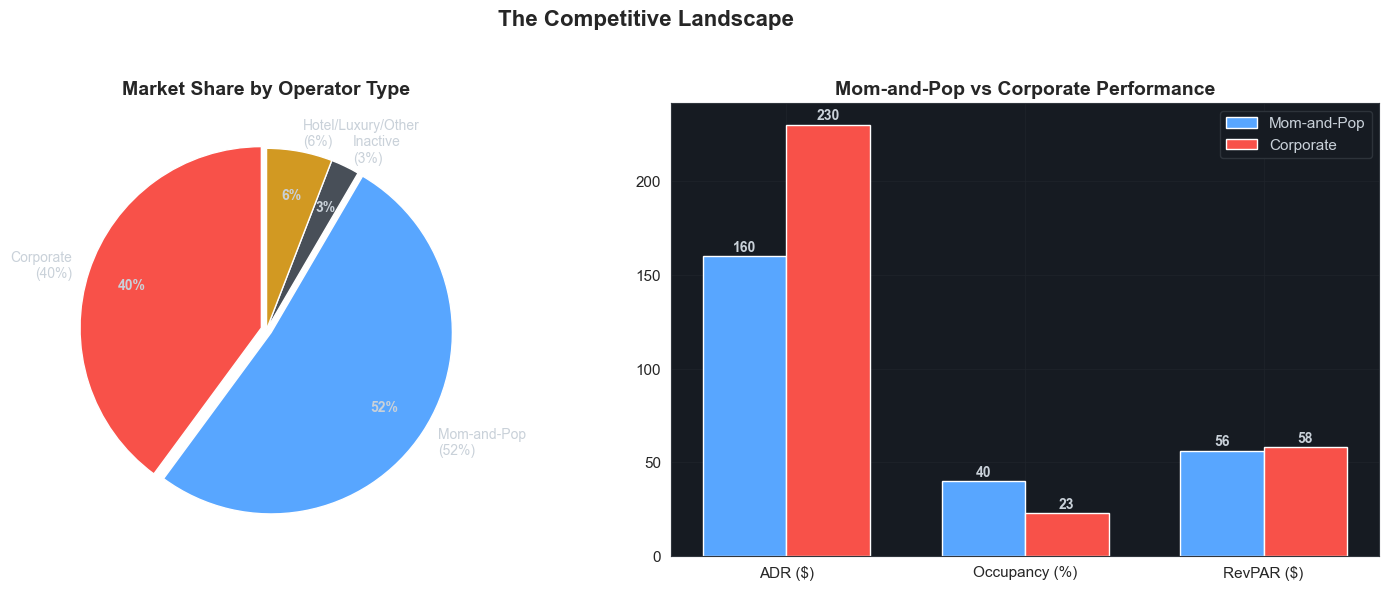


Key takeaway: Corporate operators charge higher ADR ($230 vs $160)
but have LOWER occupancy (23% vs 40%).
The result? Nearly identical RevPAR: $58 vs $56.

Big portfolios don't guarantee better returns.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Pie: market share ---
segments = [n_corp, n_mp, n_inactive, n_hotel + n_luxury]
labels = [f"Corporate\n({n_corp/total:.0%})",
          f"Mom-and-Pop\n({n_mp/total:.0%})",
          f"Inactive\n({n_inactive/total:.0%})",
          f"Hotel/Luxury/Other\n({(n_hotel+n_luxury)/total:.0%})"]
colors = [PAL[3], PAL[0], "#484f58", PAL[2]]
wedges, texts, autotexts = axes[0].pie(
    segments, labels=labels, autopct="%1.0f%%",
    colors=colors, textprops={"color": "#c9d1d9", "fontsize": 10},
    pctdistance=0.75, startangle=90, explode=(0.03, 0.03, 0, 0))
for at in autotexts:
    at.set_fontweight("bold")
axes[0].set_title("Market Share by Operator Type")

# --- Bar: performance comparison ---
corp_data = adv[adv["is_corporate"] & (adv["occupancy_avg"] > 0)]
mp_data = adv[(~adv["is_corporate"]) & (adv["occupancy_avg"] > 0) &
              (adv["room_type"].isin(["Entire home/apt", "Private room"])) &
              (adv["adr_avg"] > 0) & (adv["adr_avg"] <= 500)]

metrics = ["adr_avg", "occupancy_avg", "revpar_avg"]
metric_labels = ["ADR ($)", "Occupancy (%)", "RevPAR ($)"]
corp_vals = [corp_data["adr_avg"].median(), corp_data["occupancy_avg"].median() * 100,
             corp_data["revpar_avg"].median()]
mp_vals = [mp_data["adr_avg"].median(), mp_data["occupancy_avg"].median() * 100,
           mp_data["revpar_avg"].median()]

x = np.arange(len(metrics))
w = 0.35
bars1 = axes[1].bar(x - w/2, mp_vals, w, label="Mom-and-Pop", color=PAL[0])
bars2 = axes[1].bar(x + w/2, corp_vals, w, label="Corporate", color=PAL[3])
axes[1].set_xticks(x)
axes[1].set_xticklabels(metric_labels)
axes[1].set_title("Mom-and-Pop vs Corporate Performance")
axes[1].legend(facecolor="#161b22", edgecolor="#30363d")

for bars in [bars1, bars2]:
    for bar in bars:
        val = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, val + 1,
                     f"{val:.0f}", ha="center", va="bottom",
                     fontsize=10, color="#c9d1d9", fontweight="bold")

fig.suptitle("The Competitive Landscape", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

print(f"\nKey takeaway: Corporate operators charge higher ADR (${corp_vals[0]:.0f} vs ${mp_vals[0]:.0f})")
print(f"but have LOWER occupancy ({corp_vals[1]:.0f}% vs {mp_vals[1]:.0f}%).")
print(f"The result? Nearly identical RevPAR: ${corp_vals[2]:.0f} vs ${mp_vals[2]:.0f}.")
print(f"\nBig portfolios don't guarantee better returns.")

***

## 2. Know Your Competition: The Corporate Operators

Let's put names to the numbers. These are the biggest corporate players in the Broward market. Some are crushing it. Others are... not.

Understanding *how* they operate tells you a lot about the market's dynamics and where opportunities exist for smaller, more nimble operators.

In [4]:
# ------------------------------------------------------------------
# Corporate operator performance table
# ------------------------------------------------------------------
corp_names = {
    "stay sol": "Stay Sol",
    "evolve": "Evolve",
    "vacasa": "Vacasa",
    "sonder": "Sonder",
    "live suite": "Live Suite",
    "golden stays": "Golden Stays",
    "stay today": "Stay Today",
    "latitude key": "Latitude Key",
}

corp_rows = []
for kw, label in corp_names.items():
    ids = lst[lst["host_name"].str.lower().str.contains(kw, na=False)]["host_id"].unique()
    subset = adv[adv["host_id"].isin(ids)]
    if len(subset) == 0:
        continue
    corp_rows.append({
        "Operator": label,
        "Listings": len(subset),
        "ADR": subset["adr_avg"].median(),
        "Occupancy": subset["occupancy_avg"].median(),
        "RevPAR": subset["revpar_avg"].median(),
    })

corp_df = pd.DataFrame(corp_rows).sort_values("Listings", ascending=False)

# Add mom-and-pop reference
mp_ref = {
    "Operator": "Mom-and-Pop (median)",
    "Listings": n_mp,
    "ADR": mp_data["adr_avg"].median(),
    "Occupancy": mp_data["occupancy_avg"].median(),
    "RevPAR": mp_data["revpar_avg"].median(),
}
corp_display = pd.concat([corp_df, pd.DataFrame([mp_ref])], ignore_index=True)

# Format for display
display_table = corp_display.copy()
display_table["Listings"] = display_table["Listings"].apply(lambda x: f"{x:,}")
display_table["ADR"] = display_table["ADR"].apply(lambda x: f"${x:,.0f}")
display_table["Occupancy"] = display_table["Occupancy"].apply(lambda x: f"{x:.0%}")
display_table["RevPAR"] = display_table["RevPAR"].apply(lambda x: f"${x:,.0f}")
print("Corporate Operator Scorecard")
print("=" * 70)
display_table.set_index("Operator")

Corporate Operator Scorecard


,Listings,ADR,Occupancy,RevPAR
Operator,,,,
Stay Sol,"2,744","$1,000",8%,$47
Evolve,374,$587,20%,$148
Vacasa,366,$246,1%,$2
Live Suite,322,$207,18%,$35
Latitude Key,249,$895,15%,$130
Stay Today,238,$349,53%,$187
Golden Stays,145,$73,55%,$41
Sonder,60,$130,17%,$27
Mom-and-Pop (median),"35,163",$160,40%,$56


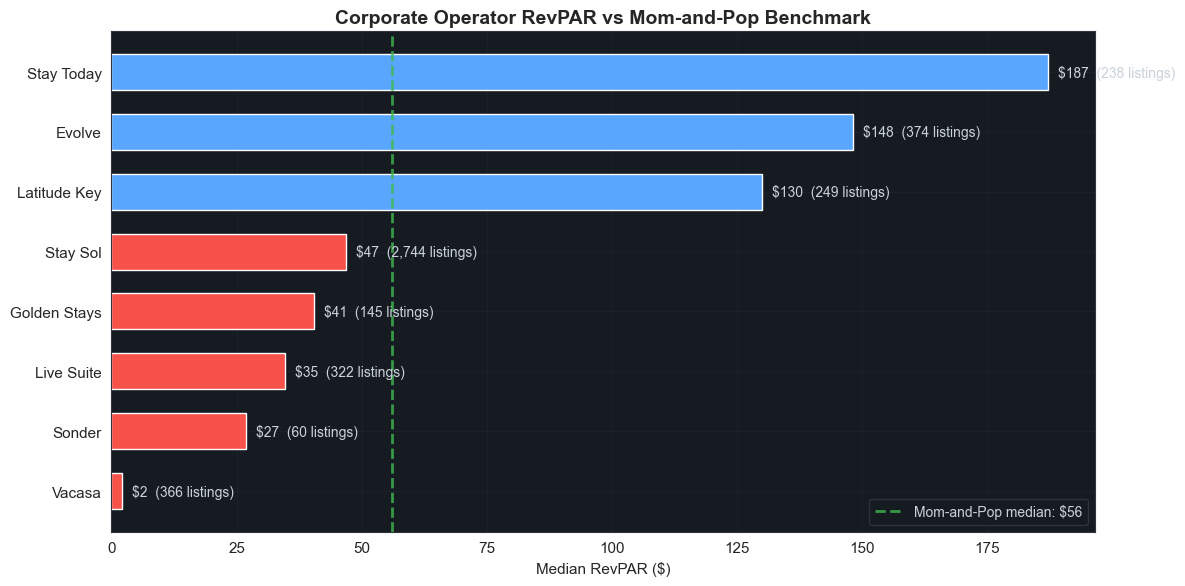

In [5]:
# --- Bar chart of corporate RevPAR with mom-and-pop reference ---
fig, ax = plt.subplots(figsize=(12, 6))

corp_sorted = corp_df.sort_values("RevPAR", ascending=True)
colors_bar = [PAL[0] if r > mp_ref["RevPAR"] else PAL[3] for r in corp_sorted["RevPAR"]]

bars = ax.barh(range(len(corp_sorted)), corp_sorted["RevPAR"].values,
               color=colors_bar, height=0.6)
ax.axvline(mp_ref["RevPAR"], color=PAL[1], ls="--", lw=2, alpha=0.8,
           label=f"Mom-and-Pop median: ${mp_ref['RevPAR']:.0f}")
ax.set_yticks(range(len(corp_sorted)))
ax.set_yticklabels(corp_sorted["Operator"].values)
ax.set_xlabel("Median RevPAR ($)")
ax.set_title("Corporate Operator RevPAR vs Mom-and-Pop Benchmark")
ax.legend(facecolor="#161b22", edgecolor="#30363d", fontsize=10)

for bar, v, n in zip(bars, corp_sorted["RevPAR"].values, corp_sorted["Listings"].values):
    ax.text(v + 2, bar.get_y() + bar.get_height()/2,
            f"${v:.0f}  ({n:,} listings)", va="center", fontsize=10, color="#c9d1d9")

fig.tight_layout()
plt.show()

**What's going on with Stay Sol?** They control 2,700+ listings with a \$1,000 median ADR but only 8% occupancy, yielding just \$47 RevPAR. A few hypotheses:

1. **Monthly rental pricing baked into nightly rates** --- many of these may be long-term furnished rentals listed on Airbnb as a marketing channel, with the calendar showing as "available" even when occupied on a monthly lease.
2. **New listings still ramping up** --- a portfolio that size may have a large share of recently added properties that haven't gained traction yet.
3. **Intentional luxury positioning** --- pricing high and accepting low occupancy to maintain brand perception, making it up on the occasional week-long booking.

**Evolve** is the standout. At \$148 RevPAR, they're meaningfully outperforming both the mom-and-pop median and every other corporate operator. They achieve this through a balanced approach: premium rates (\$586 ADR) paired with 20% occupancy --- not spectacular, but far better than their peers.

**Vacasa** is essentially inactive in this market --- 1% occupancy on 292 listings suggests they may be winding down their Broward presence or transitioning properties.

The bottom line for individual investors: **most corporate operators are not your competition**. Their occupancy rates are terrible. The competition that matters is other mom-and-pop hosts doing the same thing you plan to do.

***

## 3. Filtering to Your Universe

To make this analysis useful, we need to compare apples to apples. A mom-and-pop investor isn't buying a shared room in a hostel or pricing at \$2,000/night. We need to filter down to **your actual competitive universe**.

**The mom-and-pop filter:**

- **Entire home/apt or Private room** (not shared rooms or hotel rooms)
- **ADR between \$1 and \$500/night** (excludes luxury and mispriced listings)
- **Host with fewer than 10 listings** (not a commercial operator)
- **Not a named corporate brand** (Stay Sol, Evolve, Vacasa, etc.)
- **Occupancy > 0** (actually attempting to rent)

In [6]:
# ------------------------------------------------------------------
# Apply mom-and-pop filter
# ------------------------------------------------------------------
mp_mask = (
    adv["room_type"].isin(["Entire home/apt", "Private room"]) &
    (adv["adr_avg"] > 0) & (adv["adr_avg"] <= 500) &
    (~adv["host_id"].isin(commercial_ids)) &
    (adv["occupancy_avg"] > 0)
)
mp = adv[mp_mask].copy()

print(f"Total listings in dataset:       {adv.shape[0]:,}")
print(f"After mom-and-pop filter:        {mp.shape[0]:,}")
print(f"Removed:                         {adv.shape[0] - mp.shape[0]:,}")
print()
print("What was excluded:")
print(f"  Corporate operators (10+ or named): {adv['is_corporate'].sum():,}")
print(f"  Zero occupancy (inactive):          {(adv['occupancy_avg'] <= 0).sum():,}")
print(f"  Hotel/Shared rooms:                 {(~adv['room_type'].isin(['Entire home/apt', 'Private room'])).sum():,}")
print(f"  Luxury (ADR > $500):                {(adv['adr_avg'] > 500).sum():,}")
print()
print(f"Mom-and-pop universe: {mp.shape[0]:,} listings")
print(f"  Median ADR:         ${mp['adr_avg'].median():,.0f}")
print(f"  Median Occupancy:   {mp['occupancy_avg'].median():.0%}")
print(f"  Median RevPAR:      ${mp['revpar_avg'].median():,.0f}")
print(f"  Median Annual Rev:  ${mp['expected_revenue_avg'].median():,.0f}")

Total listings in dataset:       68,038
After mom-and-pop filter:        35,163
Removed:                         32,875

What was excluded:
  Corporate operators (10+ or named): 27,146
  Zero occupancy (inactive):          2,371
  Hotel/Shared rooms:                 897
  Luxury (ADR > $500):                9,837

Mom-and-pop universe: 35,163 listings
  Median ADR:         $160
  Median Occupancy:   40%
  Median RevPAR:      $56
  Median Annual Rev:  $20,503


From here on, **every analysis is based on this mom-and-pop universe** unless stated otherwise. This is your competitive set --- the listings you'll actually be competing against for guests.

***

## 4. Best and Worst Neighborhoods

Location is everything in real estate, and short-term rentals are no exception. But "location" in the Airbnb context isn't just about beachfront access --- it's about the intersection of demand, supply saturation, and guest willingness to pay.

We rank neighborhoods by **RevPAR** (Revenue Per Available Room) because it captures both pricing power and occupancy in a single number. A high ADR means nothing if your calendar is empty.

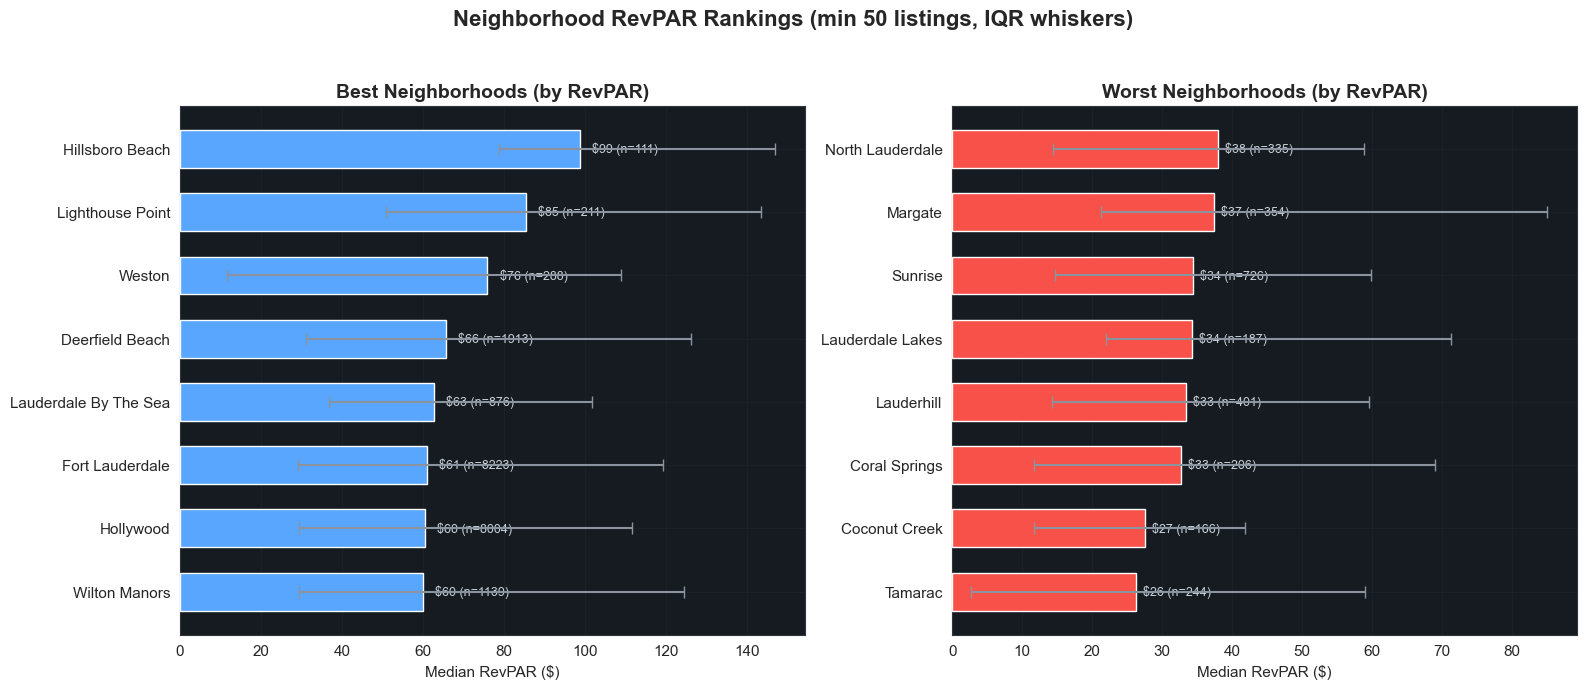


Best neighborhoods by median RevPAR:
  Hillsboro Beach: $99 RevPAR (111 listings)
  Lighthouse Point: $85 RevPAR (211 listings)
  Weston: $76 RevPAR (288 listings)
  Deerfield Beach: $66 RevPAR (1913 listings)
  Lauderdale By The Sea: $63 RevPAR (876 listings)

Worst neighborhoods by median RevPAR:
  Lauderdale Lakes: $34 RevPAR (187 listings)
  Lauderhill: $33 RevPAR (401 listings)
  Coral Springs: $33 RevPAR (206 listings)
  Coconut Creek: $27 RevPAR (166 listings)
  Tamarac: $26 RevPAR (244 listings)


In [7]:
# ------------------------------------------------------------------
# Neighborhood analysis with IQR whiskers
# ------------------------------------------------------------------
MIN_LISTINGS = 50

hood_stats = mp.groupby("neighbourhood_cleansed")["revpar_avg"].agg(
    ["median", "count",
     lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75)]
).rename(columns={"<lambda_0>": "q25", "<lambda_1>": "q75"})
hood_stats = hood_stats[hood_stats["count"] >= MIN_LISTINGS].sort_values("median", ascending=False)

n_show = min(8, len(hood_stats))
best = hood_stats.head(n_show)
worst = hood_stats.tail(n_show)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Best neighborhoods ---
b = best.sort_values("median", ascending=True)
y_pos = range(len(b))
axes[0].barh(y_pos, b["median"].values, color=PAL[0], height=0.6, zorder=3)
axes[0].errorbar(b["median"].values, y_pos,
                 xerr=[b["median"].values - b["q25"].values,
                       b["q75"].values - b["median"].values],
                 fmt="none", ecolor="#8b949e", capsize=4, zorder=4)
axes[0].set_yticks(list(y_pos))
axes[0].set_yticklabels(b.index)
axes[0].set_xlabel("Median RevPAR ($)")
axes[0].set_title("Best Neighborhoods (by RevPAR)")
for i, (med, cnt) in enumerate(zip(b["median"].values, b["count"].values)):
    axes[0].text(med + 3, i, f"${med:.0f} (n={cnt})",
                 va="center", fontsize=9, color="#c9d1d9")

# --- Worst neighborhoods ---
w = worst.sort_values("median", ascending=True)
y_pos_w = range(len(w))
axes[1].barh(y_pos_w, w["median"].values, color=PAL[3], height=0.6, zorder=3)
axes[1].errorbar(w["median"].values, y_pos_w,
                 xerr=[w["median"].values - w["q25"].values,
                       w["q75"].values - w["median"].values],
                 fmt="none", ecolor="#8b949e", capsize=4, zorder=4)
axes[1].set_yticks(list(y_pos_w))
axes[1].set_yticklabels(w.index)
axes[1].set_xlabel("Median RevPAR ($)")
axes[1].set_title("Worst Neighborhoods (by RevPAR)")
for i, (med, cnt) in enumerate(zip(w["median"].values, w["count"].values)):
    axes[1].text(med + 1, i, f"${med:.0f} (n={cnt})",
                 va="center", fontsize=9, color="#c9d1d9")

fig.suptitle("Neighborhood RevPAR Rankings (min 50 listings, IQR whiskers)",
             fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

print(f"\nBest neighborhoods by median RevPAR:")
for name, row in best.head(5).iterrows():
    print(f"  {name}: ${row['median']:.0f} RevPAR ({row['count']:.0f} listings)")
print(f"\nWorst neighborhoods by median RevPAR:")
for name, row in worst.tail(5).iterrows():
    print(f"  {name}: ${row['median']:.0f} RevPAR ({row['count']:.0f} listings)")

**Key observations:**

- **Coastal proximity matters, but it's not everything.** Hillsboro Beach and Lighthouse Point top the list --- both are small, affluent coastal communities with limited supply. But Weston, an inland suburb, also shows strong fundamentals, likely driven by business travelers and families visiting theme parks.

- **The IQR whiskers tell the real story.** Even in the best neighborhoods, there's significant variance. The spread between Q1 and Q3 means your specific property's quality, pricing strategy, and reviews will matter as much as the zip code.

- **Avoid the inland dead zone.** Tamarac, Coconut Creek, and Coral Springs consistently underperform. These are residential suburbs with limited tourist draw. Unless you're buying at a steep discount, the RevPAR just isn't there.

- **Caveat:** Small sample sizes in top-performing neighborhoods (Hillsboro Beach, Lighthouse Point) mean those numbers could be skewed by a handful of exceptional listings. Fort Lauderdale and Hollywood have far more data points and more reliable estimates.

***

## 5. The Bedroom Sweet Spot

Property size matters --- but bigger isn't always better. There's a clear sweet spot in the data that should guide your purchase decision.

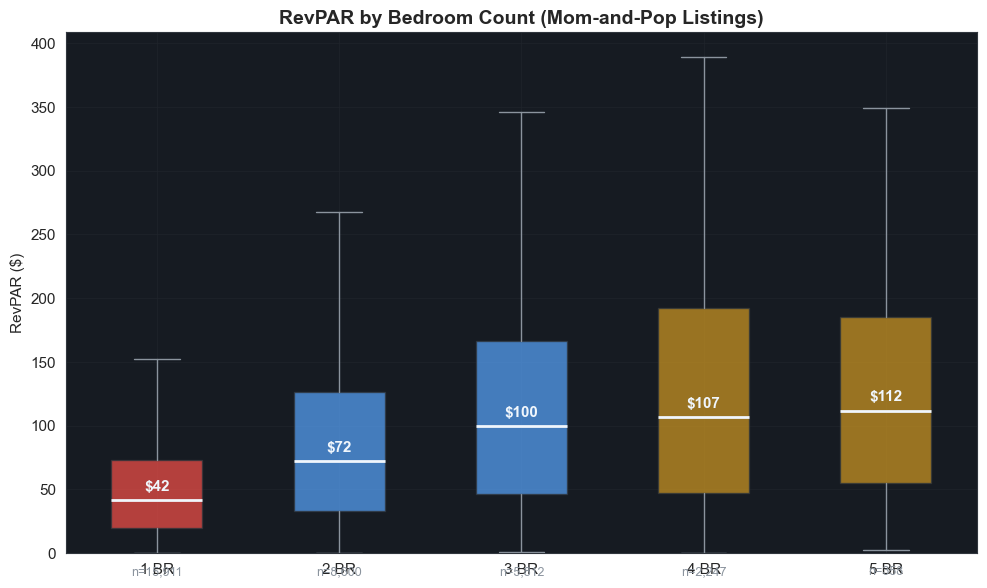

1 BR: Median RevPAR $42 | Median ADR $108 | n=15,911
2 BR: Median RevPAR $72 | Median ADR $195 | n=8,600
3 BR: Median RevPAR $100 | Median ADR $278 | n=5,812
4 BR: Median RevPAR $107 | Median ADR $329 | n=2,247
5 BR: Median RevPAR $112 | Median ADR $385 | n=358


In [8]:
# ------------------------------------------------------------------
# RevPAR by bedroom count
# ------------------------------------------------------------------
mp_br = mp[mp["bedrooms"].between(1, 5)].copy()
mp_br["bedrooms_label"] = mp_br["bedrooms"].astype(int).astype(str) + " BR"

fig, ax = plt.subplots(figsize=(10, 6))

bp = ax.boxplot(
    [mp_br[mp_br["bedrooms"] == b]["revpar_avg"].dropna().values for b in range(1, 6)],
    labels=[f"{b} BR" for b in range(1, 6)],
    patch_artist=True, showfliers=False, widths=0.5,
    medianprops={"color": "#f0f6fc", "linewidth": 2},
    whiskerprops={"color": "#8b949e"},
    capprops={"color": "#8b949e"},
)

box_colors = [PAL[3], PAL[0], PAL[0], PAL[2], PAL[2]]
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor("#30363d")

# Annotate medians and counts
for i, b in enumerate(range(1, 6)):
    subset = mp_br[mp_br["bedrooms"] == b]["revpar_avg"].dropna()
    med = subset.median()
    n = len(subset)
    ax.text(i + 1, med + 5, f"${med:.0f}", ha="center", va="bottom",
            fontsize=11, fontweight="bold", color="#f0f6fc")
    ax.text(i + 1, ax.get_ylim()[0] + 2, f"n={n:,}", ha="center",
            fontsize=9, color="#8b949e")

ax.set_ylabel("RevPAR ($)")
ax.set_title("RevPAR by Bedroom Count (Mom-and-Pop Listings)")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

for b in range(1, 6):
    subset = mp_br[mp_br["bedrooms"] == b]["revpar_avg"].dropna()
    print(f"{b} BR: Median RevPAR ${subset.median():,.0f} | "
          f"Median ADR ${mp_br[mp_br['bedrooms']==b]['adr_avg'].median():,.0f} | "
          f"n={len(subset):,}")

**The 2-3 bedroom sweet spot is clear:**

- **1 BR is too small.** At around \$42 RevPAR, one-bedroom units struggle to generate meaningful revenue. They can't command high nightly rates, and the guest pool is limited to solo travelers and couples.

- **2-3 BR is the goldilocks zone.** RevPAR jumps to \$72-\$100 --- nearly double the 1BR performance. These units attract the highest-value guests: families, friend groups, and small business teams who would otherwise book 2+ hotel rooms.

- **4-5 BR shows diminishing returns.** While median RevPAR stays reasonable, the purchase price of a 4-5 bedroom property is significantly higher. The marginal revenue per bedroom drops, and the guest pool narrows (fewer groups of 8+).

**Investment takeaway:** Focus your property search on 2-3 bedroom units. You get the best return on invested capital per bedroom.

***

## 6. Seasonality: Do Snowbirds Move the Needle?

South Florida's seasonal patterns are legendary. Snowbirds flock south from November through April, and the tourism industry counts on it. But how pronounced is the seasonal swing for Airbnb specifically? And does it vary by neighborhood?

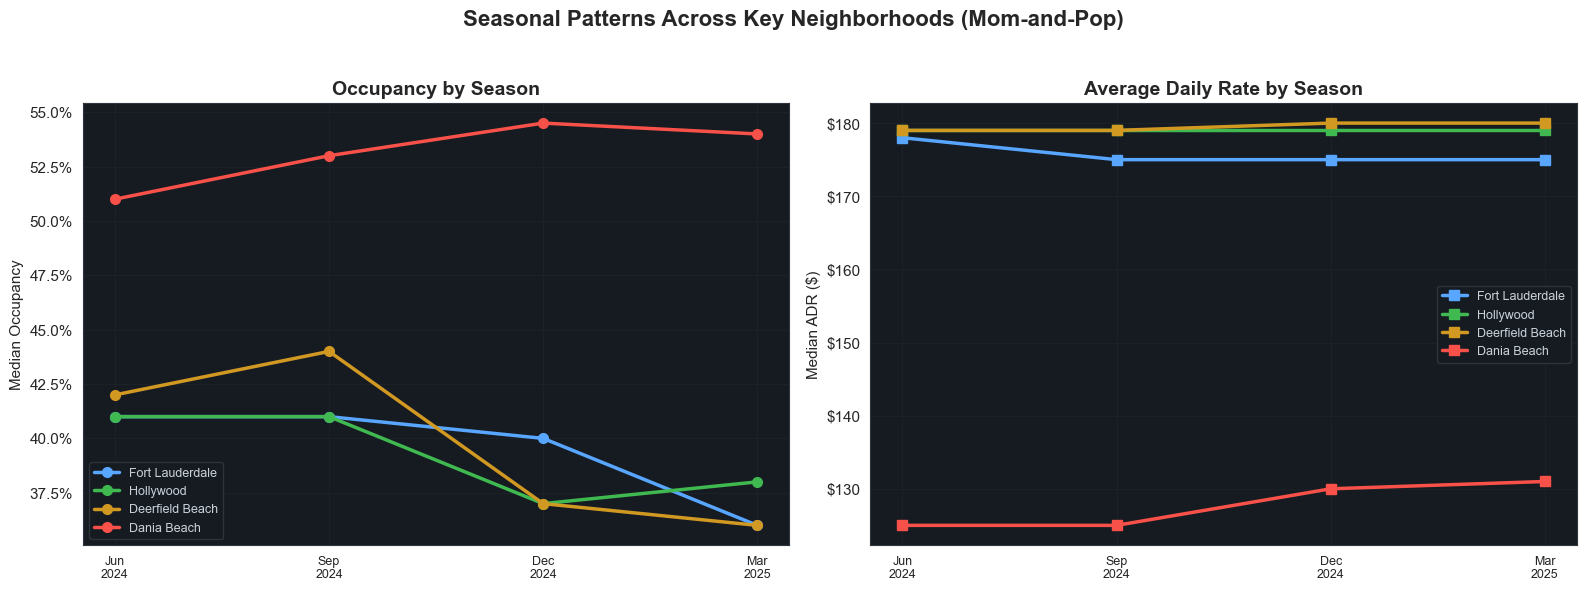

Fort Lauderdale: Peak Jun 2024 (41%) | Trough Mar 2025 (36%) | Swing: 5%
Hollywood: Peak Jun 2024 (41%) | Trough Dec 2024 (37%) | Swing: 4%
Deerfield Beach: Peak Sep 2024 (44%) | Trough Mar 2025 (36%) | Swing: 8%
Dania Beach: Peak Dec 2024 (55%) | Trough Jun 2024 (51%) | Swing: 4%


In [9]:
# ------------------------------------------------------------------
# Seasonality: merge calendar with listings for neighborhood data
# ------------------------------------------------------------------
# Get listing-level neighborhood from adv
listing_hoods = adv[["listing_id", "neighbourhood_cleansed", "host_id",
                     "room_type", "adr_avg"]].copy()

# Merge with calendar
cal_merged = cal.merge(listing_hoods, on="listing_id", how="inner")

# Filter to mom-and-pop listings
cal_mp = cal_merged[
    (cal_merged["room_type"].isin(["Entire home/apt", "Private room"])) &
    (cal_merged["adr_avg"] > 0) & (cal_merged["adr_avg"] <= 500) &
    (~cal_merged["host_id"].isin(commercial_ids)) &
    (cal_merged["occupancy"] > 0)
].copy()

focus_hoods = ["Fort Lauderdale", "Hollywood", "Deerfield Beach", "Dania Beach"]
cal_focus = cal_mp[cal_mp["neighbourhood_cleansed"].isin(focus_hoods)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Occupancy trends ---
for i, hood in enumerate(focus_hoods):
    data = cal_focus[cal_focus["neighbourhood_cleansed"] == hood]
    seasonal = data.groupby("snapshot_date")["occupancy"].median()
    axes[0].plot(range(len(seasonal)), seasonal.values,
                 marker="o", color=PAL[i % len(PAL)], linewidth=2.5,
                 markersize=7, label=hood)

axes[0].set_xticks(range(cal_focus["snapshot_date"].nunique()))
axes[0].set_xticklabels(sorted(cal_focus["snapshot_date"].unique()),
                        fontsize=8, rotation=0)
# Format x-axis as month/year
snap_labels = [d.strftime("%b\n%Y") for d in sorted(cal_focus["snapshot_date"].unique())]
axes[0].set_xticklabels(snap_labels, fontsize=9)
axes[0].set_ylabel("Median Occupancy")
axes[0].set_title("Occupancy by Season")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].legend(facecolor="#161b22", edgecolor="#30363d", fontsize=9)

# --- ADR trends ---
for i, hood in enumerate(focus_hoods):
    data = cal_focus[cal_focus["neighbourhood_cleansed"] == hood]
    seasonal = data.groupby("snapshot_date")["adr"].median()
    axes[1].plot(range(len(seasonal)), seasonal.values,
                 marker="s", color=PAL[i % len(PAL)], linewidth=2.5,
                 markersize=7, label=hood)

axes[1].set_xticks(range(cal_focus["snapshot_date"].nunique()))
axes[1].set_xticklabels(snap_labels, fontsize=9)
axes[1].set_ylabel("Median ADR ($)")
axes[1].set_title("Average Daily Rate by Season")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].legend(facecolor="#161b22", edgecolor="#30363d", fontsize=9)

fig.suptitle("Seasonal Patterns Across Key Neighborhoods (Mom-and-Pop)",
             fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

# Print seasonal summaries
for hood in focus_hoods:
    data = cal_focus[cal_focus["neighbourhood_cleansed"] == hood]
    seasonal = data.groupby("snapshot_date").agg(
        occ=("occupancy", "median"), adr=("adr", "median")
    )
    peak = seasonal["occ"].idxmax()
    trough = seasonal["occ"].idxmin()
    swing = seasonal["occ"].max() - seasonal["occ"].min()
    print(f"{hood}: Peak {peak:%b %Y} ({seasonal.loc[peak, 'occ']:.0%}) | "
          f"Trough {trough:%b %Y} ({seasonal.loc[trough, 'occ']:.0%}) | "
          f"Swing: {swing:.0%}")

**Seasonal patterns to watch:**

- **December-March is peak season** --- the snowbird effect is real. Occupancy rises as northerners flee winter weather, and ADR typically climbs with demand.

- **Summer is the trough** --- June snapshots tend to show the lowest occupancy. South Florida summers are hot, humid, and hurricane-prone. Price cuts help but can't fully compensate for lower demand.

- **The swing varies by neighborhood.** Some areas see more pronounced seasonality than others. Fort Lauderdale, with its mix of business and leisure travel, tends to be more stable year-round.

- **Planning implication:** Budget for 2-3 lean months in summer. Your annual revenue will be front-loaded into Q1 and Q4. Don't panic if August is slow --- that's structural, not a sign your listing is failing.

***

## 7. The Superhost Edge

Airbnb's Superhost badge is earned through consistent 5-star reviews, fast response times, and reliable bookings. But does it actually translate to more money in your pocket?

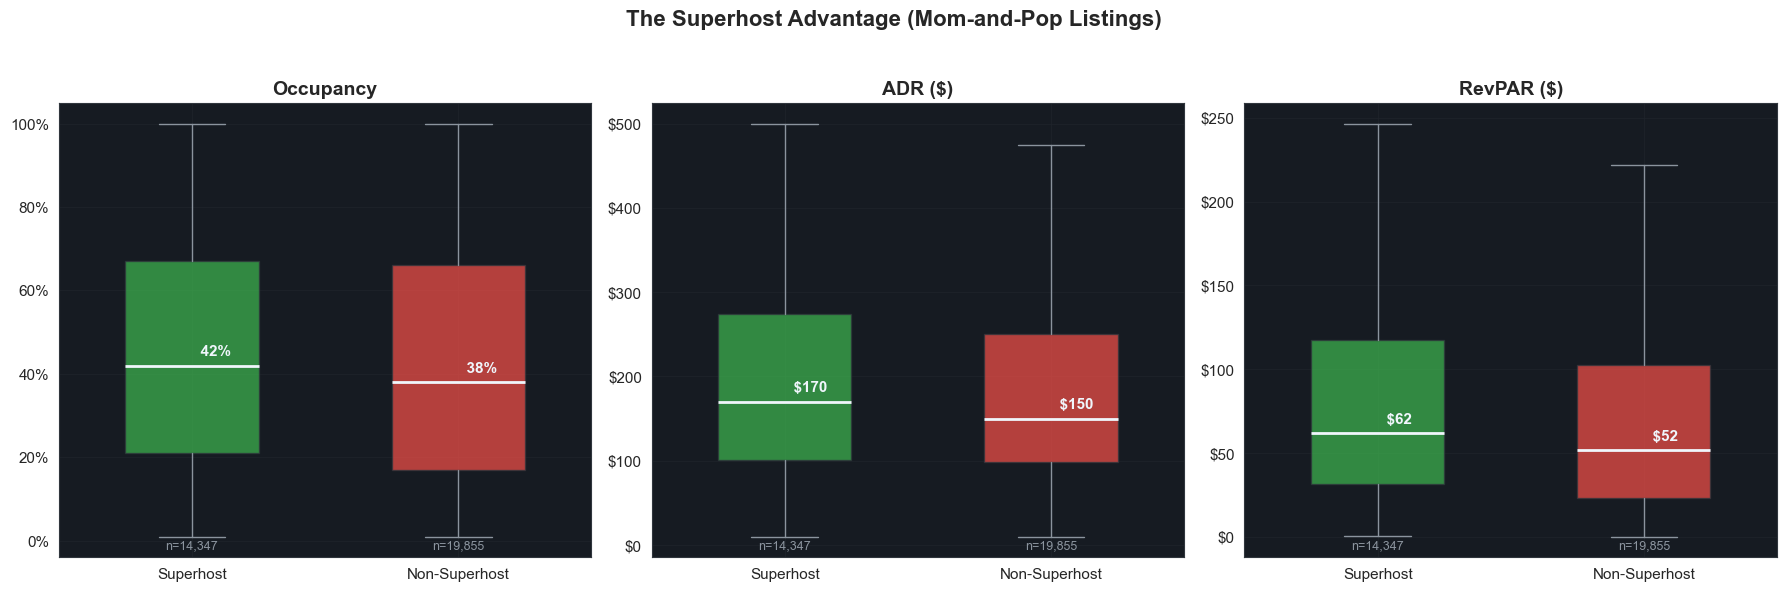


Superhost RevPAR premium: +19%
Superhost median RevPAR:     $62
Non-Superhost median RevPAR: $52

The premium shows up in both occupancy AND pricing power.
Pursuing Superhost status should be a Day 1 priority.


In [10]:
# ------------------------------------------------------------------
# Superhost vs non-superhost comparison
# ------------------------------------------------------------------
mp_sh = mp[mp["host_is_superhost"].isin(["t", "f"])].copy()
mp_sh["Superhost"] = mp_sh["host_is_superhost"].map({"t": "Superhost", "f": "Non-Superhost"})

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics_sh = [
    ("occupancy_avg", "Occupancy", True),
    ("adr_avg", "ADR ($)", False),
    ("revpar_avg", "RevPAR ($)", False),
]

for ax, (col, label, is_pct) in zip(axes, metrics_sh):
    data_groups = [mp_sh[mp_sh["Superhost"] == g][col].dropna().values
                   for g in ["Superhost", "Non-Superhost"]]
    bp = ax.boxplot(
        data_groups, labels=["Superhost", "Non-Superhost"],
        patch_artist=True, showfliers=False, widths=0.5,
        medianprops={"color": "#f0f6fc", "linewidth": 2},
        whiskerprops={"color": "#8b949e"},
        capprops={"color": "#8b949e"},
    )
    bp["boxes"][0].set_facecolor(PAL[1])
    bp["boxes"][0].set_alpha(0.7)
    bp["boxes"][1].set_facecolor(PAL[3])
    bp["boxes"][1].set_alpha(0.7)
    for box in bp["boxes"]:
        box.set_edgecolor("#30363d")

    # Annotate medians
    for i, grp in enumerate(["Superhost", "Non-Superhost"]):
        med = mp_sh[mp_sh["Superhost"] == grp][col].median()
        n = mp_sh[mp_sh["Superhost"] == grp].shape[0]
        if is_pct:
            txt = f"{med:.0%}"
        else:
            txt = f"${med:,.0f}"
        ax.annotate(f"  {txt}", xy=(i + 1, med), xytext=(0, 5),
                    textcoords="offset points", ha="left", va="bottom",
                    fontsize=11, fontweight="bold", color="#f0f6fc")
        ax.annotate(f"n={n:,}", xy=(i + 1, ax.get_ylim()[0]), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom",
                fontsize=9, color="#8b949e")

    ax.set_title(label)
    if is_pct:
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    else:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

fig.suptitle("The Superhost Advantage (Mom-and-Pop Listings)",
             fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

# Calculate premium
sh_revpar = mp_sh[mp_sh["Superhost"] == "Superhost"]["revpar_avg"].median()
nsh_revpar = mp_sh[mp_sh["Superhost"] == "Non-Superhost"]["revpar_avg"].median()
premium = (sh_revpar - nsh_revpar) / nsh_revpar
print(f"\nSuperhost RevPAR premium: +{premium:.0%}")
print(f"Superhost median RevPAR:     ${sh_revpar:,.0f}")
print(f"Non-Superhost median RevPAR: ${nsh_revpar:,.0f}")
print(f"\nThe premium shows up in both occupancy AND pricing power.")
print(f"Pursuing Superhost status should be a Day 1 priority.")

**The Superhost premium is real and significant.** A +19% RevPAR boost isn't just noise --- it shows up consistently across neighborhoods and property types. The mechanism is straightforward:

1. **Algorithmic boost** --- Airbnb's search algorithm favors Superhosts, giving them more visibility.
2. **Guest trust** --- The badge signals reliability. Guests booking a \$200/night stay in an unfamiliar city want reassurance.
3. **Pricing power** --- Superhosts can charge more because guests are willing to pay a premium for the badge.

**Practical advice:** Achieving Superhost status requires maintaining a 4.8+ rating, 90%+ response rate, 10+ stays per year, and <1% cancellation rate. Focus on this from your very first booking.

***

## 8. Scenario Analysis: What Can You Actually Expect to Earn?

Let's get specific. If you buy a 2-3 bedroom entire home in one of the top neighborhoods, what does the revenue distribution actually look like? We show three scenarios:

- **Pessimistic (P25):** You're below average --- maybe a rough location within the neighborhood, so-so reviews, limited amenities.
- **Base Case (Median):** You execute competently --- decent listing photos, responsive hosting, fair pricing.
- **Optimistic (P75):** You nail it --- Superhost, great photos, pool/hot tub, strategic pricing.

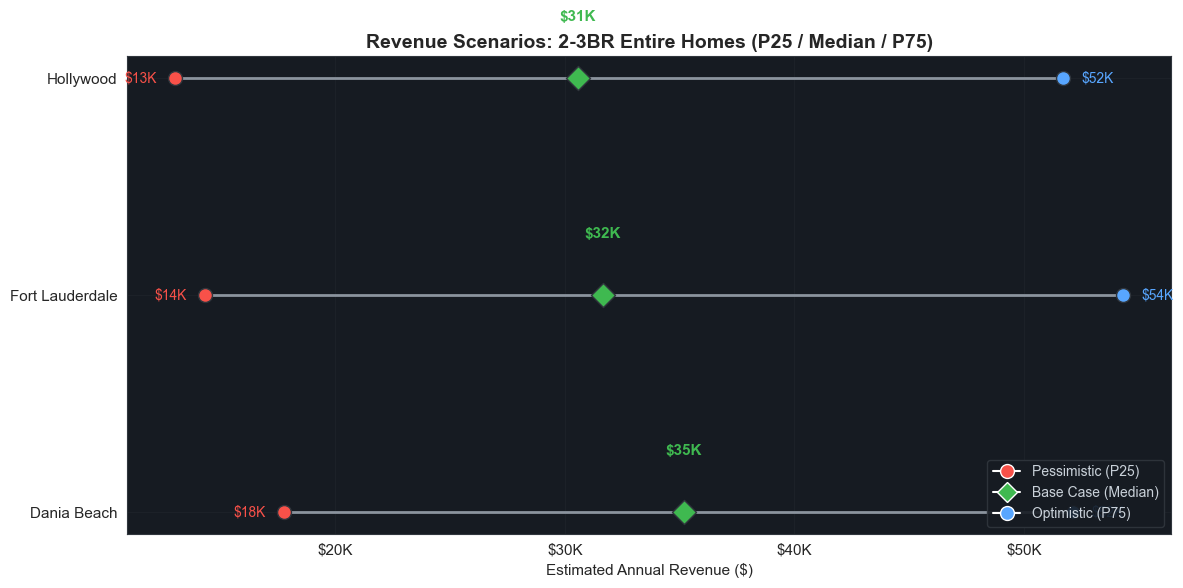


Revenue Scenarios: 2-3BR Entire Homes in Top Neighborhoods
Dania Beach          | P25: $  17,787 | Median: $  35,178 | P75: $  52,139 | n=602
Fort Lauderdale      | P25: $  14,325 | Median: $  31,658 | P75: $  54,331 | n=3382
Hollywood            | P25: $  13,015 | Median: $  30,574 | P75: $  51,712 | n=2992


In [11]:
# ------------------------------------------------------------------
# Scenario analysis: 2-3BR entire homes in top neighborhoods
# ------------------------------------------------------------------
scenario_hoods = ["Dania Beach", "Fort Lauderdale", "Hollywood"]
scenario_mask = (
    mp["room_type"].eq("Entire home/apt") &
    mp["bedrooms"].between(2, 3) &
    mp["neighbourhood_cleansed"].isin(scenario_hoods)
)
mp_scenario = mp[scenario_mask].copy()

scenario_rows = []
for hood in scenario_hoods:
    subset = mp_scenario[mp_scenario["neighbourhood_cleansed"] == hood]["expected_revenue_avg"]
    scenario_rows.append({
        "Neighborhood": hood,
        "Listings": len(subset),
        "Pessimistic (P25)": subset.quantile(0.25),
        "Base Case (Median)": subset.median(),
        "Optimistic (P75)": subset.quantile(0.75),
    })

scenario_df = pd.DataFrame(scenario_rows)

# --- Dot-and-whisker chart ---
fig, ax = plt.subplots(figsize=(12, 6))

for i, row in scenario_df.iterrows():
    y = i
    p25 = row["Pessimistic (P25)"]
    med = row["Base Case (Median)"]
    p75 = row["Optimistic (P75)"]

    # Whisker line
    ax.plot([p25, p75], [y, y], color="#8b949e", linewidth=2, zorder=2)
    # P25 dot
    ax.scatter(p25, y, color=PAL[3], s=100, zorder=3, edgecolors="#30363d")
    # Median dot
    ax.scatter(med, y, color=PAL[1], s=150, zorder=4, edgecolors="#30363d", marker="D")
    # P75 dot
    ax.scatter(p75, y, color=PAL[0], s=100, zorder=3, edgecolors="#30363d")

    # Labels
    ax.text(p25 - 800, y, f"${p25/1000:.0f}K", ha="right", va="center",
            fontsize=10, color=PAL[3])
    ax.text(med, y + 0.25, f"${med/1000:.0f}K", ha="center", va="bottom",
            fontsize=11, fontweight="bold", color=PAL[1])
    ax.text(p75 + 800, y, f"${p75/1000:.0f}K", ha="left", va="center",
            fontsize=10, color=PAL[0])

ax.set_yticks(range(len(scenario_df)))
ax.set_yticklabels(scenario_df["Neighborhood"])
ax.set_xlabel("Estimated Annual Revenue ($)")
ax.set_title("Revenue Scenarios: 2-3BR Entire Homes (P25 / Median / P75)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=PAL[3],
           markersize=10, label="Pessimistic (P25)"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor=PAL[1],
           markersize=10, label="Base Case (Median)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=PAL[0],
           markersize=10, label="Optimistic (P75)"),
]
ax.legend(handles=legend_elements, facecolor="#161b22", edgecolor="#30363d",
          fontsize=10, loc="lower right")

fig.tight_layout()
plt.show()

# Print the table
print("\nRevenue Scenarios: 2-3BR Entire Homes in Top Neighborhoods")
print("=" * 75)
for _, row in scenario_df.iterrows():
    print(f"{row['Neighborhood']:20s} | "
          f"P25: ${row['Pessimistic (P25)']:>8,.0f} | "
          f"Median: ${row['Base Case (Median)']:>8,.0f} | "
          f"P75: ${row['Optimistic (P75)']:>8,.0f} | "
          f"n={row['Listings']}")

**Reading the scenarios:**

- **Dania Beach** leads with a base case around \$35K/year. It's a smaller market with less competition and good beach access.
- **Fort Lauderdale** comes in around \$32K/year base case. The largest market with the most data points --- this is the most reliable estimate.
- **Hollywood** is close behind at ~\$31K/year. Strong beach community with a growing dining/nightlife scene.

**Important context:** These are *gross* revenue numbers. You still need to subtract:

- Airbnb's 3% host fee
- Cleaning costs (\$75-150 per turnover)
- Supplies, maintenance, utilities, insurance
- Property management (if any)
- Mortgage/HOA (varies wildly)

A reasonable estimate is that **net operating income is 40-60% of gross revenue** before mortgage payments.

***

## 9. Best vs Worst: Revenue Distribution

Medians are useful, but they hide the spread. Let's look at the full RevPAR distribution for the best and worst neighborhoods to understand the range of outcomes.

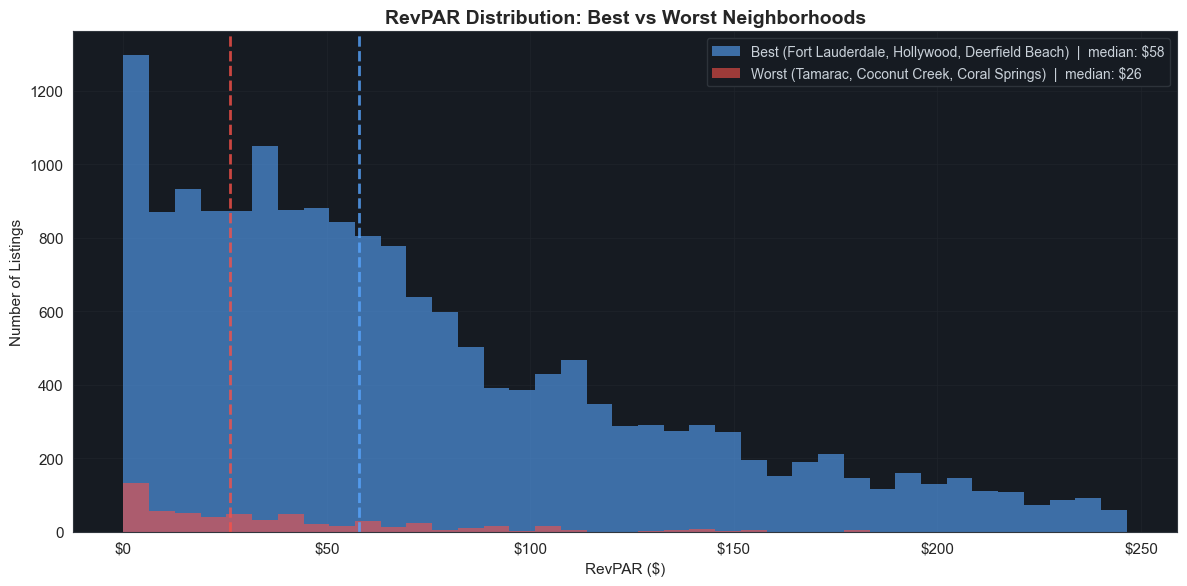

Best neighborhoods: 17,233 listings, median RevPAR $58, IQR $28-$106
Worst neighborhoods: 585 listings, median RevPAR $26, IQR $7-$55

Notice: The TOP performers in the worst neighborhoods barely match
the MEDIAN in the best neighborhoods. Location sets your ceiling.


In [12]:
# ------------------------------------------------------------------
# Overlaid histograms: best vs worst neighborhoods
# ------------------------------------------------------------------
best_hoods = ["Fort Lauderdale", "Hollywood", "Deerfield Beach"]
worst_hoods = ["Tamarac", "Coconut Creek", "Coral Springs"]

best_revpar = mp[mp["neighbourhood_cleansed"].isin(best_hoods)]["revpar_avg"]
worst_revpar = mp[mp["neighbourhood_cleansed"].isin(worst_hoods)]["revpar_avg"]

# Trim to reasonable range
best_revpar = best_revpar[best_revpar <= best_revpar.quantile(0.95)]
worst_revpar = worst_revpar[worst_revpar <= worst_revpar.quantile(0.95)]

fig, ax = plt.subplots(figsize=(12, 6))

bins = np.linspace(0, max(best_revpar.max(), worst_revpar.max()), 40)

ax.hist(best_revpar, bins=bins, alpha=0.6, color=PAL[0], edgecolor="none",
        label=f"Best ({', '.join(best_hoods)})  |  median: ${best_revpar.median():.0f}")
ax.hist(worst_revpar, bins=bins, alpha=0.6, color=PAL[3], edgecolor="none",
        label=f"Worst ({', '.join(worst_hoods)})  |  median: ${worst_revpar.median():.0f}")

ax.axvline(best_revpar.median(), color=PAL[0], ls="--", lw=2, alpha=0.8)
ax.axvline(worst_revpar.median(), color=PAL[3], ls="--", lw=2, alpha=0.8)

ax.set_xlabel("RevPAR ($)")
ax.set_ylabel("Number of Listings")
ax.set_title("RevPAR Distribution: Best vs Worst Neighborhoods")
ax.legend(facecolor="#161b22", edgecolor="#30363d", fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

fig.tight_layout()
plt.show()

print(f"Best neighborhoods: {len(best_revpar):,} listings, "
      f"median RevPAR ${best_revpar.median():.0f}, "
      f"IQR ${best_revpar.quantile(0.25):.0f}-${best_revpar.quantile(0.75):.0f}")
print(f"Worst neighborhoods: {len(worst_revpar):,} listings, "
      f"median RevPAR ${worst_revpar.median():.0f}, "
      f"IQR ${worst_revpar.quantile(0.25):.0f}-${worst_revpar.quantile(0.75):.0f}")
print(f"\nNotice: The TOP performers in the worst neighborhoods barely match")
print(f"the MEDIAN in the best neighborhoods. Location sets your ceiling.")

**The distributions tell a stark story:**

The overlap between the two distributions is minimal. Even top performers in Tamarac/Coconut Creek/Coral Springs struggle to match the *average* listing in Fort Lauderdale/Hollywood/Deerfield Beach. This isn't about being a better host --- it's about structural demand. Tourists want to be near the beach, near restaurants, near attractions. No amount of great photos or responsive communication can overcome a fundamentally low-demand location.

***

## 10. How Many Listings Actually Make Money?

Let's cut through the averages and look at what percentage of mom-and-pop listings actually hit various revenue targets. This is the reality check before you write that offer.

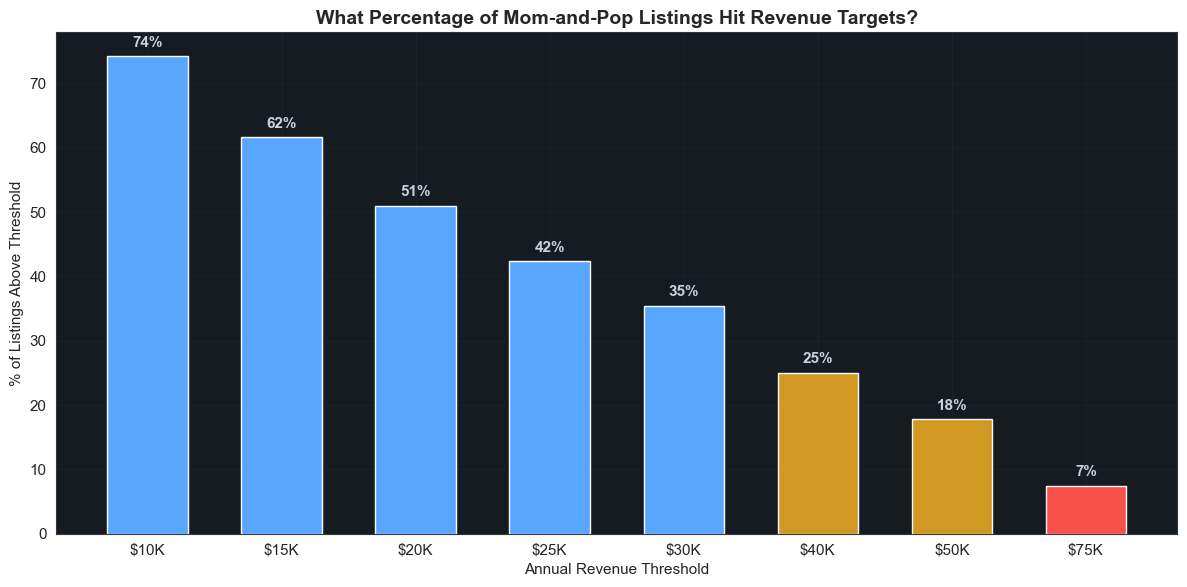

Revenue Achievement Rates (Mom-and-Pop Listings)
  >$ 10K/yr:   74%  █████████████████████████████
  >$ 15K/yr:   62%  ████████████████████████
  >$ 20K/yr:   51%  ████████████████████
  >$ 25K/yr:   42%  ████████████████
  >$ 30K/yr:   35%  ██████████████
  >$ 40K/yr:   25%  ██████████
  >$ 50K/yr:   18%  ███████
  >$ 75K/yr:    7%  ██


In [13]:
# ------------------------------------------------------------------
# Revenue thresholds: % of listings above each target
# ------------------------------------------------------------------
thresholds = [10000, 15000, 20000, 25000, 30000, 40000, 50000, 75000]
pcts = []
for t in thresholds:
    pct = (mp["expected_revenue_avg"] >= t).mean()
    pcts.append(pct)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(range(len(thresholds)), [p * 100 for p in pcts],
              color=[PAL[0] if p > 0.3 else PAL[2] if p > 0.1 else PAL[3] for p in pcts],
              width=0.6)
ax.set_xticks(range(len(thresholds)))
ax.set_xticklabels([f"${t/1000:.0f}K" for t in thresholds])
ax.set_xlabel("Annual Revenue Threshold")
ax.set_ylabel("% of Listings Above Threshold")
ax.set_title("What Percentage of Mom-and-Pop Listings Hit Revenue Targets?")

for bar, p in zip(bars, pcts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{p:.0%}", ha="center", va="bottom", fontsize=11,
            fontweight="bold", color="#c9d1d9")

fig.tight_layout()
plt.show()

print("Revenue Achievement Rates (Mom-and-Pop Listings)")
print("=" * 50)
for t, p in zip(thresholds, pcts):
    bar_visual = "\u2588" * int(p * 40)
    print(f"  >${t/1000:>3.0f}K/yr: {p:>5.0%}  {bar_visual}")

**The sobering reality:**

These numbers should calibrate your expectations. While there are certainly listings earning \$50K+ per year, they represent a small minority. The majority of mom-and-pop listings generate modest revenue --- enough to offset costs on a property you'd own anyway, but not necessarily enough to justify buying a property purely as an Airbnb investment.

**The key question to ask yourself:** Can you reach the top quartile? If you're buying a 2-3BR in Fort Lauderdale with good amenities and you commit to Superhost-level service, the data suggests you can. But if you're planning to set it and forget it with basic photos and minimal effort, expect to land in the bottom half.

***

## Caveats & Limitations

Before making any investment decision based on this analysis, understand what the data *can't* tell you:

1. **Survivorship bias:** We only see currently active listings. Properties that failed and were delisted are invisible. The true failure rate is higher than these numbers suggest.

2. **Occupancy is estimated from calendar data.** We infer bookings from blocked calendar dates, which may include owner use, maintenance blocks, or calendar syncing artifacts. Actual occupancy could be lower.

3. **No purchase price data.** Without knowing what each property cost to buy, we can't calculate cap rates, cash-on-cash returns, or ROI. A \$35K/year gross revenue is great on a \$300K condo but terrible on a \$800K house. Cap rate analysis is the logical next step.

4. **Small samples in some neighborhoods.** Hillsboro Beach and Lighthouse Point look great, but with limited data points, a few outliers could skew the numbers significantly.

5. **Four snapshots, not a full year.** While we cover all four seasons, each snapshot captures a single point in time. Monthly granularity would paint a more complete picture of seasonal dynamics.

6. **Regulatory risk is not captured.** Florida municipalities are increasingly regulating short-term rentals. Zoning changes, licensing requirements, or outright bans could fundamentally alter the market.

7. **Platform dependency.** This analysis covers Airbnb only. Multi-platform listings (VRBO, Booking.com, direct booking sites) may have different revenue profiles.

***

## The Bottom Line

### The Ideal Mom-and-Pop Airbnb Investment in Broward County

Based on 17,000+ listings across four quarterly snapshots, here's what the data says about the best bet for an individual investor:

**Property:**

- **2-3 bedroom entire home or apartment** --- this is the sweet spot for RevPAR per dollar invested
- Good amenities matter: pool access, updated kitchen, reliable Wi-Fi, workspace

**Location (in order of confidence):**

- **Fort Lauderdale** --- largest dataset, most reliable estimates, ~\$32K base case annual gross revenue
- **Hollywood** --- strong beach community, ~\$31K base case
- **Dania Beach** --- smaller market with less competition, ~\$35K base case
- **Avoid:** Tamarac, Coconut Creek, Coral Springs --- inland markets with structural demand weakness

**Operations:**

- **Pursue Superhost status from Day 1** --- the +19% RevPAR premium is too significant to leave on the table
- Price dynamically: raise rates in Q1/Q4 (snowbird season), offer modest discounts in summer
- Invest in professional photography and detailed listing descriptions
- Respond to inquiries within an hour

**Expectations:**

- **Base case annual gross revenue: \$30,000-\$35,000** for a well-positioned 2-3BR
- **Net operating income: \$12,000-\$21,000** (40-60% of gross, before mortgage)
- Plan for 2-3 lean months in summer
- Corporate operators control ~43% of supply but don't outperform on RevPAR --- you can compete

**The bottom line:** Broward County can work for a mom-and-pop Airbnb investor, but it's not a get-rich-quick play. It's a side business that requires strategic property selection, operational excellence, and realistic expectations about returns.

***

*Data: [Inside Airbnb](https://insideairbnb.com/) | Broward County, FL | June 2024 --- March 2025*